In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
import time

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving eruption.txt to eruption.txt


In [ ]:
data = pd.read_csv(
    "eruption.txt",
    sep=r"\s+",
    header=None
)

data.columns = ["ID", "Eruption", "Waiting"]

print(data.head())
print("\nDataset Shape:", data.shape)

   ID  Eruption  Waiting
0   1     3.600       79
1   2     1.800       54
2   3     3.333       74
3   4     2.283       62
4   5     4.533       85

Dataset Shape: (272, 3)


In [ ]:
print("Missing Values:")
print(data.isnull().sum())

Missing Values:
ID          0
Eruption    0
Waiting     0
dtype: int64


In [ ]:
data.dropna()

,ID,Eruption,Waiting
0,1,3.600,79
1,2,1.800,54
2,3,3.333,74
3,4,2.283,62
4,5,4.533,85
...,...,...,...
267,268,4.117,81
268,269,2.150,46
269,270,4.417,90
270,271,1.817,46


In [ ]:
print("Duplicate Rows:", data.duplicated().sum())

Duplicate Rows: 0


In [ ]:
X = data[["Eruption", "Waiting"]].values

In [ ]:
print("Feature Matrix Shape:", X.shape)

Feature Matrix Shape: (272, 2)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Dataset:")
print(X_scaled[:5])

print("\nMean:", X_scaled.mean(axis=0))
print("Standard Deviation:", X_scaled.std(axis=0))

Scaled Dataset:
[[ 0.09849886  0.59712344]
 [-1.48145856 -1.24518118]
 [-0.13586149  0.22866251]
 [-1.05750332 -0.6556437 ]
 [ 0.91744345  1.03927655]]

Mean: [4.80008190e-16 4.40823848e-16]
Standard Deviation: [1. 1.]


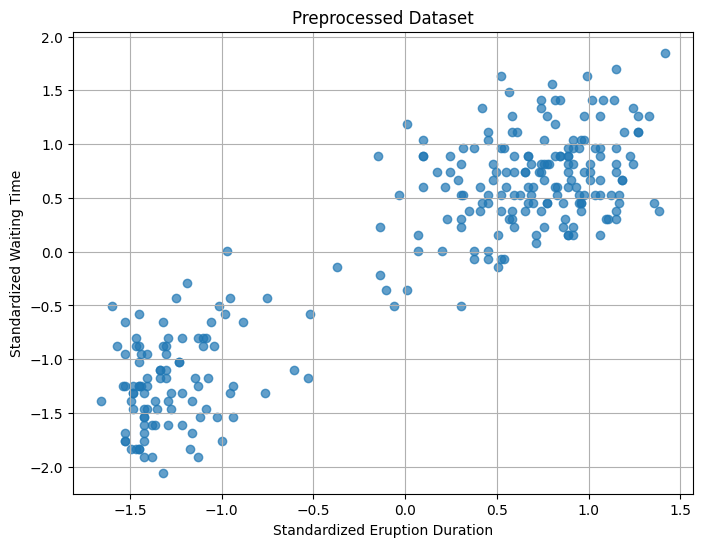

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    alpha=0.7
)

plt.xlabel("Standardized Eruption Duration")
plt.ylabel("Standardized Waiting Time")

plt.title("Preprocessed Dataset")

plt.grid(True)
plt.show()

In [ ]:
# GMM using Scikit-learn's predefined GaussianMixture model

def em_algorithm(X, K, initialization="random",
                 max_iter=100, tol=1e-4, random_state=42):

    start_time = time.time()

    gmm = GaussianMixture(
        n_components=K,
        covariance_type="full",
        init_params=initialization,
        n_init=1,
        max_iter=max_iter,
        tol=tol,
        random_state=random_state
    )

    gmm.fit(X)

    labels = gmm.predict(X)
    responsibilities = gmm.predict_proba(X)

    # Total log-likelihood across all observations
    log_likelihood = gmm.score(X) * len(X)

    execution_time = time.time() - start_time

    return {
        "weights": gmm.weights_,
        "means": gmm.means_,
        "covariances": gmm.covariances_,
        "responsibilities": responsibilities,
        "labels": labels,
        "log_likelihood": log_likelihood,
        "log_likelihood_history": [],
        "iterations": gmm.n_iter_,
        "converged": gmm.converged_,
        "execution_time": execution_time,
        "model": gmm
    }


In [ ]:
# Step 7.3: Run EM with Random Initialization

random_result = em_algorithm(
    X_scaled,
    K=2,
    initialization="random",
    random_state=42
)

print("\n========== RANDOM INITIALIZATION RESULTS ==========")

print("Final Log-Likelihood:",
      random_result["log_likelihood"])

print("Iterations:",
      random_result["iterations"])

print("Execution Time:",
      random_result["execution_time"])

print("Cluster Sizes:",
      np.bincount(random_result["labels"]))


# Run EM with K-Means Initialization

kmeans_result = em_algorithm(
    X_scaled,
    K=2,
    initialization="kmeans",
    random_state=42
)

print("\n========== K-MEANS INITIALIZATION RESULTS ==========")

print("Final Log-Likelihood:",
      kmeans_result["log_likelihood"])

print("Iterations:",
      kmeans_result["iterations"])

print("Execution Time:",
      kmeans_result["execution_time"])

print("Cluster Sizes:",
      np.bincount(kmeans_result["labels"]))



========== RANDOM INITIALIZATION RESULTS ==========
Final Log-Likelihood: -544.9511706785627
Iterations: 3
Execution Time: 0.01827406883239746
Cluster Sizes: [129 143]

========== K-MEANS INITIALIZATION RESULTS ==========
Final Log-Likelihood: -385.460701739437
Iterations: 4
Execution Time: 0.01466226577758789
Cluster Sizes: [175  97]


In [ ]:
# Step 8.1: Draw Gaussian Covariance Ellipses

from matplotlib.patches import Ellipse

def draw_ellipse(mean, covariance, ax, color):

    # Calculate eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)

    # Sort in descending order
    order = eigenvalues.argsort()[::-1]

    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    # Calculate ellipse angle
    angle = np.degrees(
        np.arctan2(eigenvectors[1, 0],
                   eigenvectors[0, 0])
    )

    # Calculate width and height
    width, height = 2 * 2 * np.sqrt(eigenvalues)

    # Create ellipse
    ellipse = Ellipse(
        xy=mean,
        width=width,
        height=height,
        angle=angle,
        edgecolor=color,
        facecolor="none",
        linewidth=2
    )

    ax.add_patch(ellipse)

In [ ]:
# Step 8.2: Visualize GMM Clustering

def plot_gmm(X, result, title):

    fig, ax = plt.subplots(figsize=(9, 6))

    labels = result["labels"]
    means = result["means"]
    covariances = result["covariances"]

    # Scatter plot
    scatter = ax.scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        cmap="viridis",
        s=40,
        alpha=0.7
    )

    # Plot Gaussian means and covariance ellipses
    for k in range(len(means)):

        draw_ellipse(
            means[k],
            covariances[k],
            ax,
            color=f"C{k}"
        )

        ax.scatter(
            means[k, 0],
            means[k, 1],
            marker="X",
            s=200,
            edgecolor="black",
            label=f"Gaussian {k+1} Mean"
        )

    ax.set_xlabel("Standardized Eruption Duration")
    ax.set_ylabel("Standardized Waiting Time")

    ax.set_title(title)

    ax.legend()
    ax.grid(True)

    plt.show()


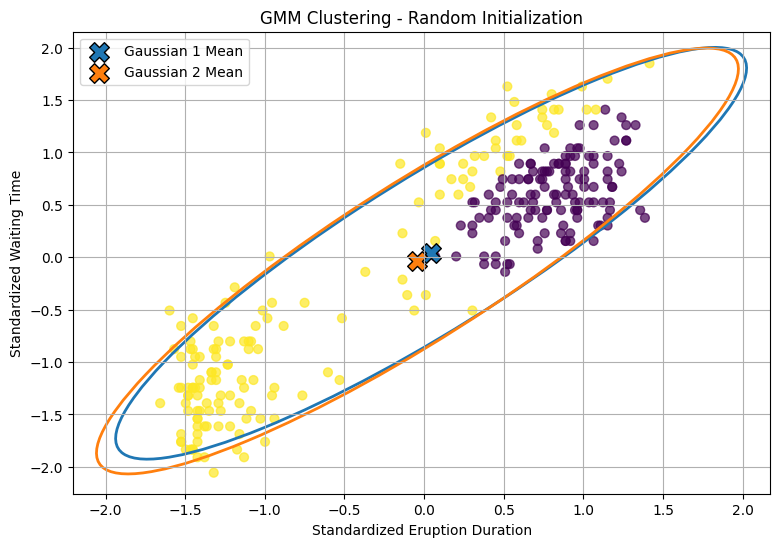

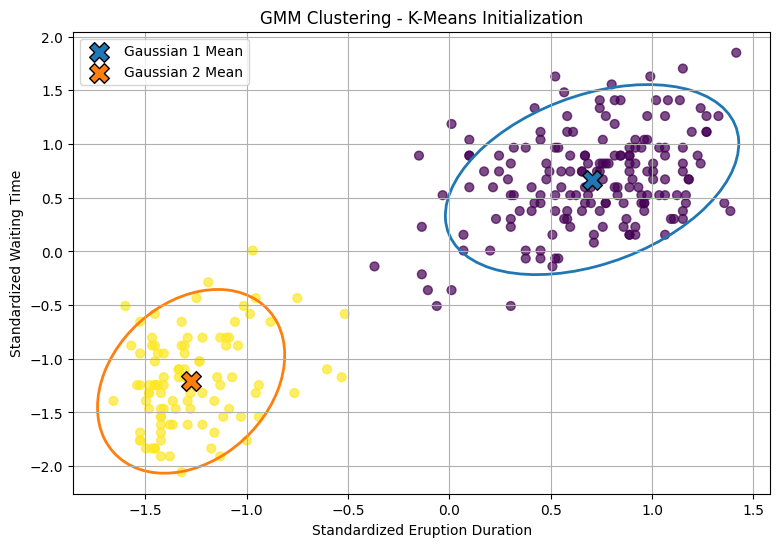

In [ ]:
# Step 8.3: Plot Random Initialization Results

plot_gmm(
    X_scaled,
    random_result,
    "GMM Clustering - Random Initialization"
)

# Plot K-Means Initialization Results

plot_gmm(
    X_scaled,
    kmeans_result,
    "GMM Clustering - K-Means Initialization"
)

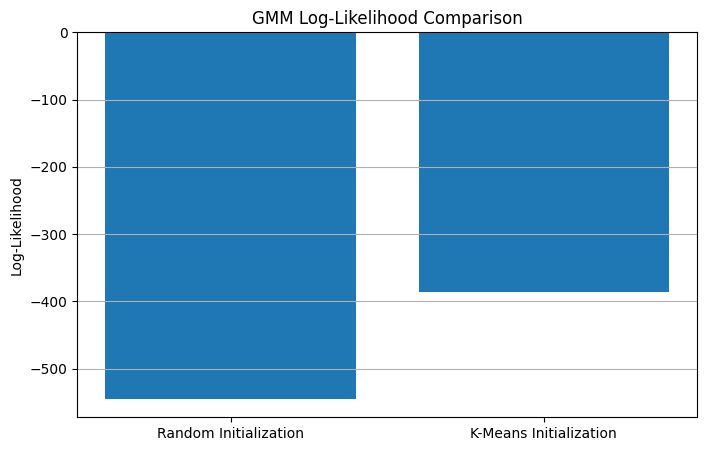

In [ ]:
# Initialization Comparison

methods = [
    "Random Initialization",
    "K-Means Initialization"
]

likelihoods = [
    random_result["log_likelihood"],
    kmeans_result["log_likelihood"]
]

plt.figure(figsize=(8, 5))

plt.bar(methods, likelihoods)

plt.ylabel("Log-Likelihood")
plt.title("GMM Log-Likelihood Comparison")

plt.grid(axis="y")

plt.show()

In [ ]:
from sklearn.metrics import silhouette_score
# Step 10: Performance Evaluation

def evaluate_gmm(X, result):

    labels = result["labels"]

    # Calculate Silhouette Score
    silhouette = silhouette_score(X, labels)

    # Collect evaluation results
    metrics = {
        "Log-Likelihood": result["log_likelihood"],
        "Silhouette Score": silhouette,
        "ARI": "N/A",
        "NMI": "N/A",
        "Iterations": result["iterations"],
        "Execution Time": result["execution_time"]
    }

    return metrics

In [ ]:
# Evaluate Random Initialization

random_metrics = evaluate_gmm(
    X_scaled,
    random_result
)

# Evaluate K-Means Initialization

kmeans_metrics = evaluate_gmm(
    X_scaled,
    kmeans_result
)

In [ ]:
# Create comparison DataFrame

comparison = pd.DataFrame(
    {
        "Random Initialization": random_metrics,
        "K-Means Initialization": kmeans_metrics
    }
)

print("\n========== PERFORMANCE COMPARISON ==========")

print(comparison)


========== PERFORMANCE COMPARISON ==========
                 Random Initialization K-Means Initialization
Log-Likelihood             -544.951171            -385.460702
Silhouette Score              0.450405               0.746002
ARI                                N/A                    N/A
NMI                                N/A                    N/A
Iterations                           3                      4
Execution Time                0.018274               0.014662


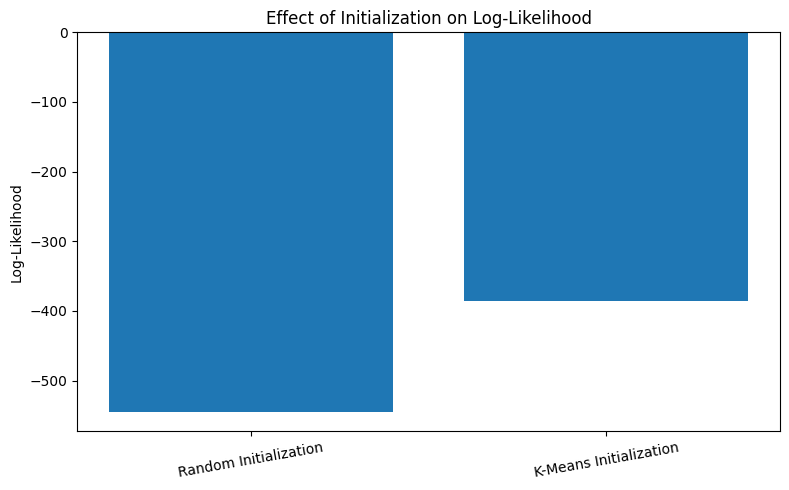

In [ ]:
# Experiment 1: Initialization Comparison

methods = [
    "Random Initialization",
    "K-Means Initialization"
]

log_likelihoods = [
    random_result["log_likelihood"],
    kmeans_result["log_likelihood"]
]

iterations = [
    random_result["iterations"],
    kmeans_result["iterations"]
]

execution_times = [
    random_result["execution_time"],
    kmeans_result["execution_time"]
]

plt.figure(figsize=(8, 5))

plt.bar(methods, log_likelihoods)

plt.ylabel("Log-Likelihood")
plt.title("Effect of Initialization on Log-Likelihood")

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [ ]:
# Experiment 2: Different Number of Components

K_values = [2, 3, 4, 5]

results_K = {}
comparison_K = []

for K in K_values:

    start_time = time.time()

    result = em_algorithm(
        X_scaled,
        K=K,
        initialization="kmeans",
        max_iter=200
    )

    results_K[K] = result

    silhouette = silhouette_score(
        X_scaled,
        result["labels"]
    )

    comparison_K.append({
        "K": K,
        "Log-Likelihood": result["log_likelihood"],
        "Silhouette Score": silhouette,
        "Iterations": result["iterations"],
        "Converged": result["converged"],
        "Execution Time": result["execution_time"]
    })

    print(f"\n========== K = {K} ==========")

    print("Log-Likelihood:", result["log_likelihood"])
    print("Silhouette Score:", silhouette)
    print("Iterations:", result["iterations"])
    print("Execution Time:", result["execution_time"])


comparison_K_df = pd.DataFrame(comparison_K)

print("\n========== K COMPARISON ==========")

print(comparison_K_df)


========== K = 2 ==========
Log-Likelihood: -385.460701739437
Silhouette Score: 0.7460024896679954
Iterations: 4
Execution Time: 0.013881444931030273

========== K = 3 ==========
Log-Likelihood: -374.5243946647805
Silhouette Score: 0.5605543548632608
Iterations: 61
Execution Time: 0.0691063404083252

========== K = 4 ==========
Log-Likelihood: -370.39104757547716
Silhouette Score: 0.421374188109422
Iterations: 27
Execution Time: 0.03619718551635742

========== K = 5 ==========
Log-Likelihood: -357.6515564339455
Silhouette Score: 0.2414409100777571
Iterations: 59
Execution Time: 0.07927441596984863

========== K COMPARISON ==========
   K  Log-Likelihood  Silhouette Score  Iterations  Converged  Execution Time
0  2     -385.460702          0.746002           4       True        0.013881
1  3     -374.524395          0.560554          61       True        0.069106
2  4     -370.391048          0.421374          27       True        0.036197
3  5     -357.651556          0.241441        

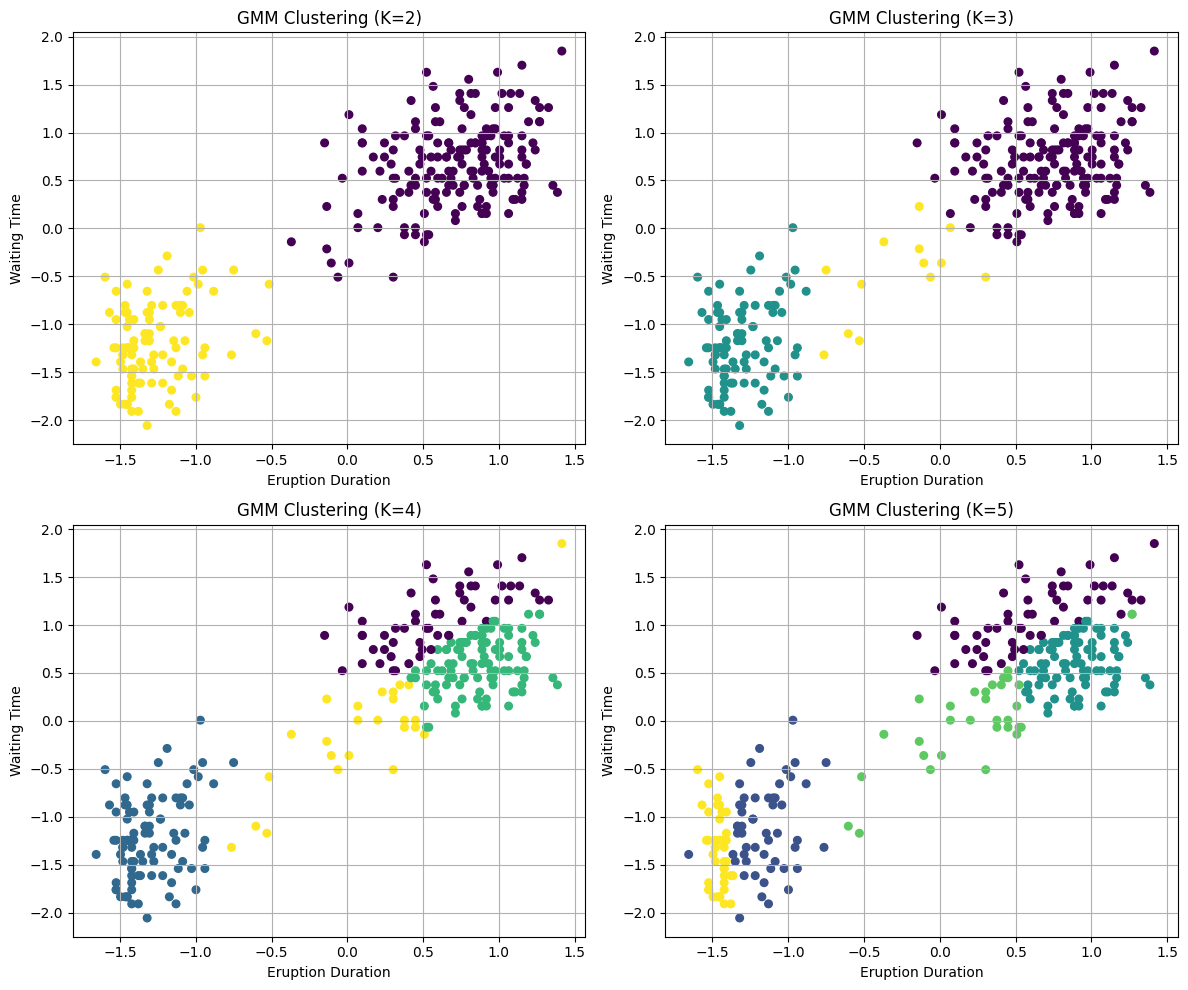

In [ ]:
# Visual Comparison for Different K Values

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, K in zip(axes.flat, K_values):

    result = results_K[K]

    ax.scatter(
        X_scaled[:, 0],
        X_scaled[:, 1],
        c=result["labels"],
        cmap="viridis",
        s=30
    )

    ax.set_title(f"GMM Clustering (K={K})")

    ax.set_xlabel("Eruption Duration")
    ax.set_ylabel("Waiting Time")

    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Experiment 3.1: Generate datasets with different overlap levels

from sklearn.datasets import make_blobs

def generate_overlap_dataset(separation):

    X_synthetic, true_labels = make_blobs(
        n_samples=400,
        centers=[
            [-separation, 0],
            [separation, 0]
        ],
        cluster_std=1.5,
        random_state=42
    )

    return X_synthetic, true_labels


overlap_levels = {
    "Low Overlap": 5,
    "Medium Overlap": 2.5,
    "High Overlap": 1
}

In [ ]:
# Experiment 3.2: Evaluate different overlap levels

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

overlap_results = {}

for name, separation in overlap_levels.items():

    X_synthetic, true_labels = generate_overlap_dataset(separation)

    result = em_algorithm(
        X_synthetic,
        K=2,
        initialization="kmeans",
        max_iter=100
    )

    ari = adjusted_rand_score(
        true_labels,
        result["labels"]
    )

    nmi = normalized_mutual_info_score(
        true_labels,
        result["labels"]
    )

    silhouette = silhouette_score(
        X_synthetic,
        result["labels"]
    )

    overlap_results[name] = {
        "ARI": ari,
        "NMI": nmi,
        "Silhouette": silhouette,
        "Log-Likelihood": result["log_likelihood"],
        "Iterations": result["iterations"]
    }

    print(f"\n========== {name} ==========")

    print("ARI:", ari)
    print("NMI:", nmi)
    print("Silhouette Score:", silhouette)
    print("Log-Likelihood:", result["log_likelihood"])
    print("Iterations:", result["iterations"])


========== Low Overlap ==========
ARI: 1.0
NMI: 1.0
Silhouette Score: 0.7351316075223403
Log-Likelihood: -1721.9498365685151
Iterations: 2

========== Medium Overlap ==========
ARI: 0.7826804620525026
NMI: 0.6832040132881076
Silhouette Score: 0.5134275392128592
Log-Likelihood: -1670.409728318586
Iterations: 4

========== High Overlap ==========
ARI: 0.14225369948261515
NMI: 0.10708353848097588
Silhouette Score: 0.3360166144039873
Log-Likelihood: -1511.878909605436
Iterations: 13


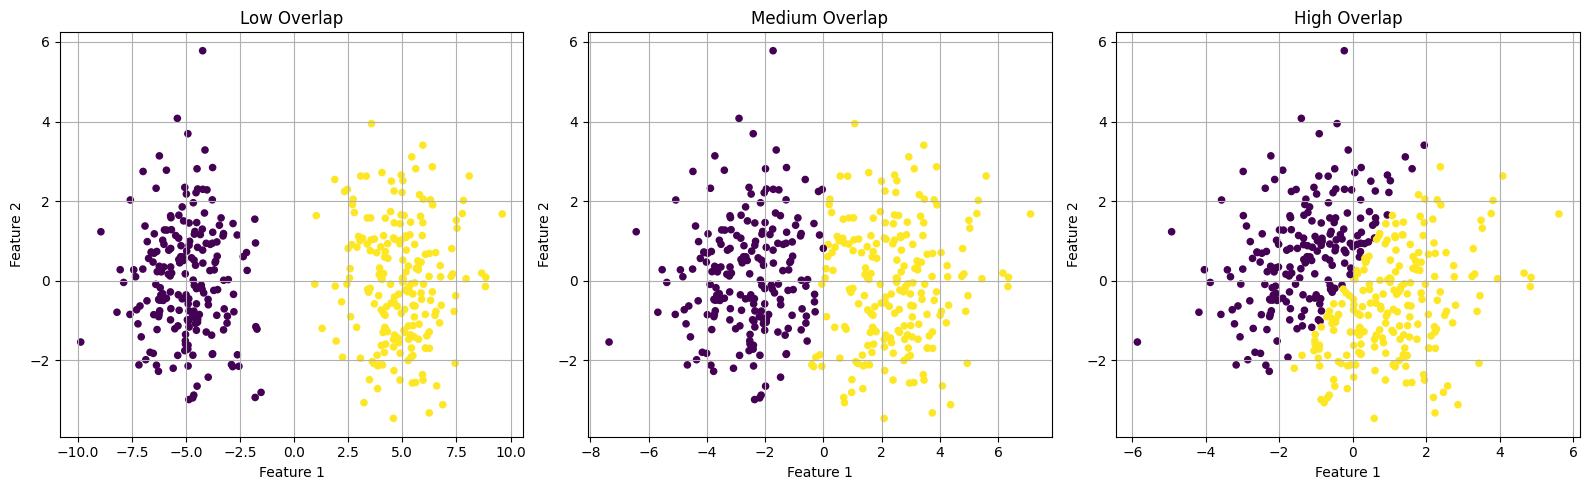

In [ ]:
# Experiment 3.3: Visualize overlap levels

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, separation) in zip(
    axes,
    overlap_levels.items()
):

    X_synthetic, true_labels = generate_overlap_dataset(separation)

    result = em_algorithm(
        X_synthetic,
        K=2,
        initialization="kmeans"
    )

    ax.scatter(
        X_synthetic[:, 0],
        X_synthetic[:, 1],
        c=result["labels"],
        cmap="viridis",
        s=20
    )

    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Experiment 3.4: Comparison Table

overlap_df = pd.DataFrame(overlap_results).T

print("\n========== OVERLAP COMPARISON ==========")

print(overlap_df)


========== OVERLAP COMPARISON ==========
                     ARI       NMI  Silhouette  Log-Likelihood  Iterations
Low Overlap     1.000000  1.000000    0.735132    -1721.949837         2.0
Medium Overlap  0.782680  0.683204    0.513428    -1670.409728         4.0
High Overlap    0.142254  0.107084    0.336017    -1511.878910        13.0


In [ ]:
# Experiment 4.1: Run GMM 10 times with different random initializations

random_runs = []

for run in range(10):

    result = em_algorithm(
        X_scaled,
        K=2,
        initialization="random",
        max_iter=100,
        tol=1e-4,
        random_state=run
    )

    silhouette = silhouette_score(
        X_scaled,
        result["labels"]
    )

    random_runs.append({
        "Run": run + 1,
        "Log-Likelihood": result["log_likelihood"],
        "Silhouette Score": silhouette,
        "Iterations": result["iterations"],
        "Converged": result["converged"],
        "Execution Time": result["execution_time"]
    })

    print(
        f"Run {run + 1}: "
        f"Log-Likelihood = {result['log_likelihood']:.4f}, "
        f"Iterations = {result['iterations']}, "
        f"Converged = {result['converged']}"
    )


Run 1: Log-Likelihood = -544.8786, Iterations = 3, Converged = True
Run 2: Log-Likelihood = -544.9808, Iterations = 2, Converged = True
Run 3: Log-Likelihood = -385.4608, Iterations = 26, Converged = True
Run 4: Log-Likelihood = -544.9600, Iterations = 2, Converged = True
Run 5: Log-Likelihood = -544.9119, Iterations = 3, Converged = True
Run 6: Log-Likelihood = -544.9840, Iterations = 3, Converged = True
Run 7: Log-Likelihood = -385.4607, Iterations = 29, Converged = True
Run 8: Log-Likelihood = -545.0075, Iterations = 3, Converged = True
Run 9: Log-Likelihood = -544.9656, Iterations = 2, Converged = True
Run 10: Log-Likelihood = -544.9868, Iterations = 2, Converged = True


In [ ]:
# Step 14.2: Display results

random_runs_df = pd.DataFrame(random_runs)

print("\n========== TEN RANDOM INITIALIZATION RUNS ==========")

print(random_runs_df)

print("\n========== STATISTICAL SUMMARY ==========")

print(
    random_runs_df[
        ["Log-Likelihood", "Silhouette Score",
         "Iterations", "Execution Time"]
    ].agg(["mean", "std", "min", "max"])
)


========== TEN RANDOM INITIALIZATION RUNS ==========
   Run  Log-Likelihood  Silhouette Score  Iterations  Converged  \
0    1     -544.878554          0.718248           3       True   
1    2     -544.980763          0.551525           2       True   
2    3     -385.460761          0.746002          26       True   
3    4     -544.959995          0.468502           2       True   
4    5     -544.911923          0.059357           3       True   
5    6     -544.983961          0.071842           3       True   
6    7     -385.460742          0.746002          29       True   
7    8     -545.007509          0.068874           3       True   
8    9     -544.965623          0.429318           2       True   
9   10     -544.986792          0.365367           2       True   

   Execution Time  
0        0.011673  
1        0.006895  
2        0.028828  
3        0.007279  
4        0.011796  
5        0.008232  
6        0.030907  
7        0.006942  
8        0.006026  
9       

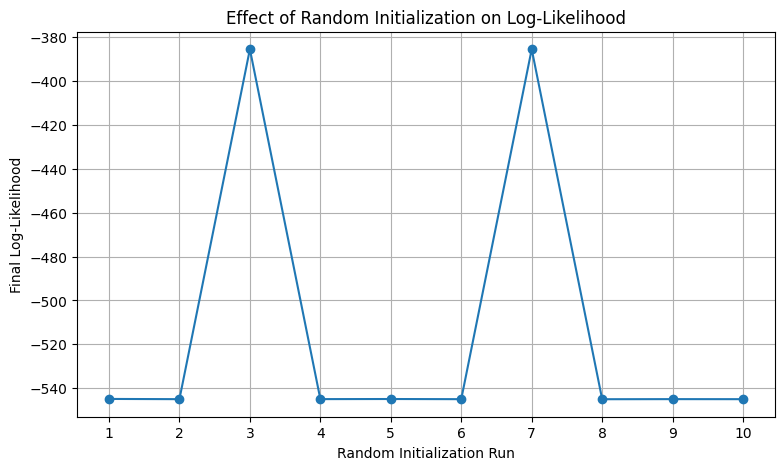

In [ ]:
# Step 14.3: Log-likelihood variation

plt.figure(figsize=(9, 5))

plt.plot(
    random_runs_df["Run"],
    random_runs_df["Log-Likelihood"],
    marker="o"
)

plt.xlabel("Random Initialization Run")
plt.ylabel("Final Log-Likelihood")

plt.title("Effect of Random Initialization on Log-Likelihood")

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()